Best Parameters: {'svm__C': 0.1, 'svm__kernel': 'linear'}
Accuracy: 0.9111111111111111
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.82      0.93      0.88        15
           2       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



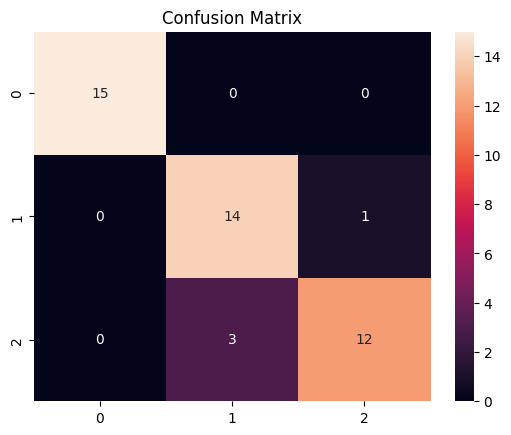

Cross Validation Scores: [0.96666667 0.96666667 0.96666667 0.93333333 1.        ]
Mean Accuracy: 0.9666666666666666


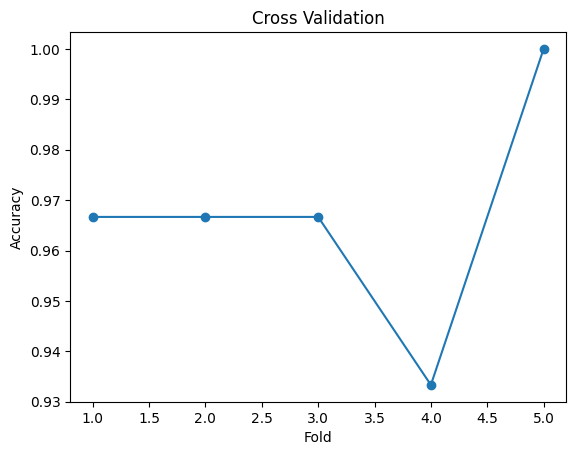

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

parameters = {
    "svm__C": [0.1, 1, 10],
    "svm__kernel": ["linear", "rbf"]
}

grid = GridSearchCV(model, parameters, cv=5)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
predictions = best_model.predict(X_test)

print("Best Parameters:", grid.best_params_)
print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

scores = cross_val_score(best_model, X, y, cv=5)

print("Cross Validation Scores:", scores)
print("Mean Accuracy:", np.mean(scores))

plt.plot(range(1, 6), scores, marker="o")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Cross Validation")
plt.show()